# Event Organizer (EO) Sales Conversion & Revenue Analysis

## Project Overview
* This project presents an Exploratory Data Analysis (EDA) on 1,000 Event Organizer (EO) client inquiries to evaluate deal closing rates, realized revenue performance, venue preferences, seasonal booking patterns, and package tier conversion drivers.
* **Environment & Tools:** Python, Pandas, Matplotlib, Seaborn.
* **Dataset Scope:** 1,000 client prospect records across 9 initial attributes, detailing client age (`usia`), venue distance (`jarak_km`), proposed budget (`budget_juta`), guest count (`jumlah_undangan`), venue type (`jenis_venue`), wedding season (`musim_nikah`), catering tier (`level_catering`), decoration style (`jenis_dekorasi`), and final deal status (`deal_jadi`).

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("/content/drive/MyDrive/umacoding/data analis/client_eo.csv")
data

,usia,jarak_km,budget_juta,jumlah_undangan,jenis_venue,musim_nikah,level_catering,jenis_dekorasi,deal_jadi
0,27,28,92,538,Outdoor,Kemarau,Silver,Rustic,1
1,22,34,66,495,Outdoor,Hujan,Basic,Rustic,0
2,23,5,118,421,Outdoor,Hujan,Basic,Rustic,1
3,24,8,71,679,Outdoor,Hujan,Basic,Rustic,0
4,26,14,283,960,Indoor,Kemarau,Gold,Minimalis,0
...,...,...,...,...,...,...,...,...,...
995,44,15,373,1652,Pantai,Akhir_Tahun,Platinum,Modern_Mewah,1
996,30,7,195,776,Gedung,Kemarau,Gold,Minimalis,1
997,35,54,213,1117,Pantai,Kemarau,Silver,Rustic,0
998,31,16,153,1155,Indoor,Kemarau,Silver,Minimalis,0


In [ ]:
print(data.columns)
print(data.dtypes)
print(data.isnull().sum())

data.drop_duplicates(inplace=True)
print("Total baris bersih:", len(data))

data["Budget_per_undangan_ribu"] = (data["budget_juta"] * 1000) / data["jumlah_undangan"]
data["Revenue_terealisasi_juta"] = data["budget_juta"] * data["deal_jadi"]

print("Total potensi pipeline (Juta Rp):", data["budget_juta"].sum())
print("Total revenue terealisasi (Juta Rp):", data["Revenue_terealisasi_juta"].sum())
print("Total potensi hilang (Juta Rp):", data["budget_juta"].sum() - data["Revenue_terealisasi_juta"].sum())

data

Index(['usia', 'jarak_km', 'budget_juta', 'jumlah_undangan', 'jenis_venue',
       'musim_nikah', 'level_catering', 'jenis_dekorasi', 'deal_jadi'],
      dtype='object')
usia                int64
jarak_km            int64
budget_juta         int64
jumlah_undangan     int64
jenis_venue        object
musim_nikah        object
level_catering     object
jenis_dekorasi     object
deal_jadi           int64
dtype: object
usia               0
jarak_km           0
budget_juta        0
jumlah_undangan    0
jenis_venue        0
musim_nikah        0
level_catering     0
jenis_dekorasi     0
deal_jadi          0
dtype: int64
Total baris bersih: 1000
Total potensi pipeline (Juta Rp): 244940
Total revenue terealisasi (Juta Rp): 180330
Total potensi hilang (Juta Rp): 64610


,usia,jarak_km,budget_juta,jumlah_undangan,jenis_venue,musim_nikah,level_catering,jenis_dekorasi,deal_jadi,Budget_per_undangan_ribu,Revenue_terealisasi_juta
0,27,28,92,538,Outdoor,Kemarau,Silver,Rustic,1,171.003717,92
1,22,34,66,495,Outdoor,Hujan,Basic,Rustic,0,133.333333,0
2,23,5,118,421,Outdoor,Hujan,Basic,Rustic,1,280.285036,118
3,24,8,71,679,Outdoor,Hujan,Basic,Rustic,0,104.565538,0
4,26,14,283,960,Indoor,Kemarau,Gold,Minimalis,0,294.791667,0
...,...,...,...,...,...,...,...,...,...,...,...
995,44,15,373,1652,Pantai,Akhir_Tahun,Platinum,Modern_Mewah,1,225.786925,373
996,30,7,195,776,Gedung,Kemarau,Gold,Minimalis,1,251.288660,195
997,35,54,213,1117,Pantai,Kemarau,Silver,Rustic,0,190.689346,0
998,31,16,153,1155,Indoor,Kemarau,Silver,Minimalis,0,132.467532,0


## Data Cleaning & Feature Engineering
* **Missing Value & Duplicate Audit:** Initial verification via `data.isnull().sum()` and `data.drop_duplicates(inplace=True)` confirmed zero missing values and zero duplicate records across all 1,000 client inquiries.
* **Feature Engineering:** Formulated two commercial sales metrics to evaluate deal efficiency and realized revenue:
  * `Budget_per_undangan_ribu`: Client budget allocation per invited guest in Thousands IDR (`(budget_juta * 1,000) / jumlah_undangan`).
  * `Revenue_terealisasi_juta`: Actual closed revenue in Millions IDR (`budget_juta * deal_jadi`), separating closed deals (`Rp 180,330 million`) from lost pipeline opportunities (`Rp 64,610 million`).

   deal_jadi  count
0          1    682
1          0    318


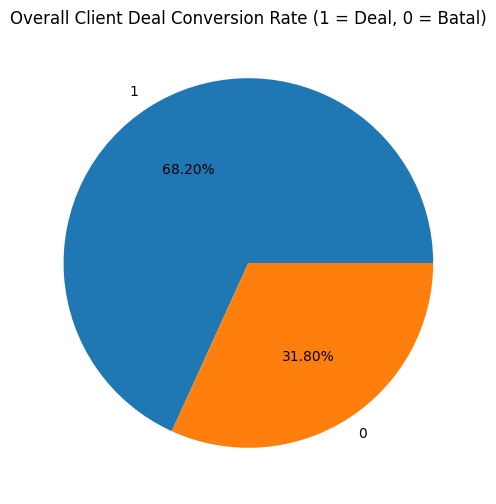

In [ ]:
deal_status = data["deal_jadi"].value_counts().reset_index()
print(deal_status)

plt.figure(figsize=(6, 6))
plt.pie(deal_status["count"], labels=deal_status["deal_jadi"], autopct="%1.2f%%")
plt.title("Overall Client Deal Conversion Rate (1 = Deal, 0 = Batal)", fontsize=12)
plt.show()

## Exploratory Data Analysis & Key Insights

### A. Overall Client Deal Conversion Rate
Evaluating final deal outcomes across all 1,000 client inquiries revealed a strong baseline conversion rate alongside substantial unrealized pipeline value:
* **Closed Deals (`1`):** Accounted for 682 inquiries, representing a **68.20%** overall conversion rate and generating **Rp 180,330 million** in realized revenue.
* **Lost / Canceled Deals (`0`):** Comprised 318 inquiries (**31.80%**), resulting in **Rp 64,610 million** of unrealized sales pipeline.

  jenis_venue  Total_prospek  Total_deal  Revenue_juta  Conversion_rate
0      Gedung            247         196         63518         0.793522
1      Indoor            129          93         21250         0.720930
2     Outdoor            250         127         12476         0.508000
3      Pantai            374         266         83086         0.711230


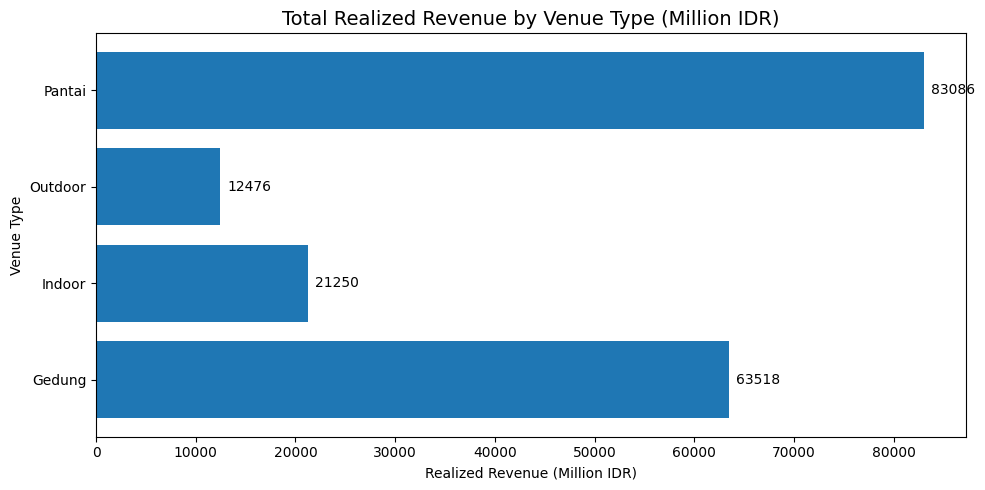

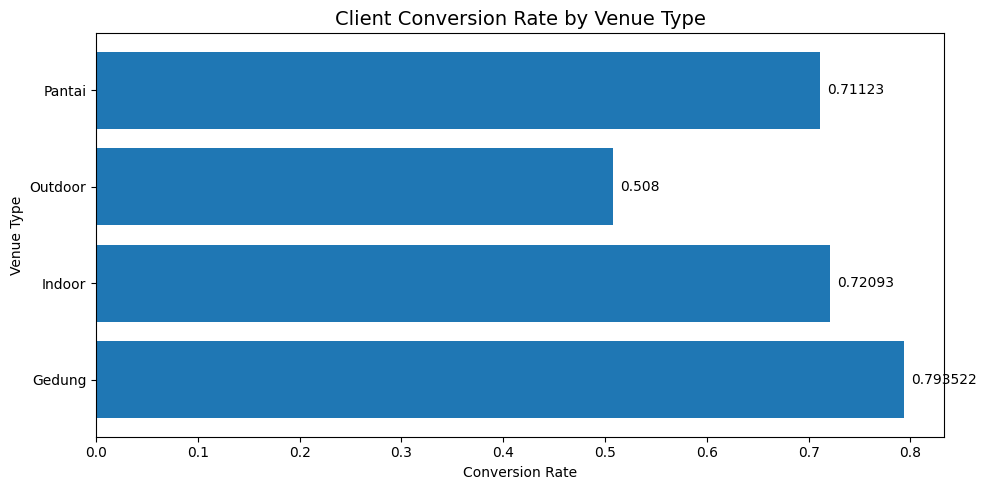

In [ ]:
venue_total = data.groupby("jenis_venue")["deal_jadi"].count().reset_index()
venue_deal = data.groupby("jenis_venue")["deal_jadi"].sum().reset_index()
venue_rev = data.groupby("jenis_venue")["Revenue_terealisasi_juta"].sum().reset_index()
venue_rate = data.groupby("jenis_venue")["deal_jadi"].mean().reset_index()

venue_summary = venue_total.merge(venue_deal, on="jenis_venue")
venue_summary = venue_summary.merge(venue_rev, on="jenis_venue")
venue_summary = venue_summary.merge(venue_rate, on="jenis_venue")
venue_summary.columns = ["jenis_venue", "Total_prospek", "Total_deal", "Revenue_juta", "Conversion_rate"]
print(venue_summary)

# Grafik 1: Total Realized Revenue per Jenis Venue
plt.figure(figsize=(10, 5))
bars_rev = plt.barh(venue_summary["jenis_venue"], venue_summary["Revenue_juta"])
plt.bar_label(bars_rev, padding=5)
plt.title("Total Realized Revenue by Venue Type (Million IDR)", fontsize=14)
plt.xlabel("Realized Revenue (Million IDR)")
plt.ylabel("Venue Type")
plt.tight_layout()
plt.show()

# Grafik 2: Conversion Rate per Jenis Venue
plt.figure(figsize=(10, 5))
bars_rate = plt.barh(venue_summary["jenis_venue"], venue_summary["Conversion_rate"])
plt.bar_label(bars_rate, padding=5)
plt.title("Client Conversion Rate by Venue Type", fontsize=14)
plt.xlabel("Conversion Rate")
plt.ylabel("Venue Type")
plt.tight_layout()
plt.show()

### B. Realized Revenue & Conversion Performance by Venue Type
Comparing inquiry volume, closing rates, and realized revenue across venue categories exposed a major conversion bottleneck in outdoor events:
* **Pantai (Beach):** Generated the highest inquiry volume (374 leads) and highest total realized revenue at **Rp 83,086 million** (266 deals; **71.12%** conversion rate).
* **Gedung (Ballroom/Hall):** Achieved the highest closing efficiency at **79.35%** (196 deals out of 247 leads) and ranked second in revenue with **Rp 63,518 million**.
* **Indoor:** Maintained a solid **72.09%** conversion rate (93 deals out of 129 leads), contributing **Rp 21,250 million**.
* **Outdoor:** Recorded the lowest conversion rate at only **50.80%** (127 deals out of 250 leads) and lowest revenue at **Rp 12,476 million**—nearly half of all outdoor inquiries failed to close.

Conversion Rate per Musim:
    musim_nikah  deal_jadi
0  Akhir_Tahun   0.731915
1        Hujan   0.591270
2      Kemarau   0.703704

Realized Revenue per Musim:
    musim_nikah  Revenue_terealisasi_juta
0  Akhir_Tahun                     57264
1        Hujan                     26264
2      Kemarau                     96802


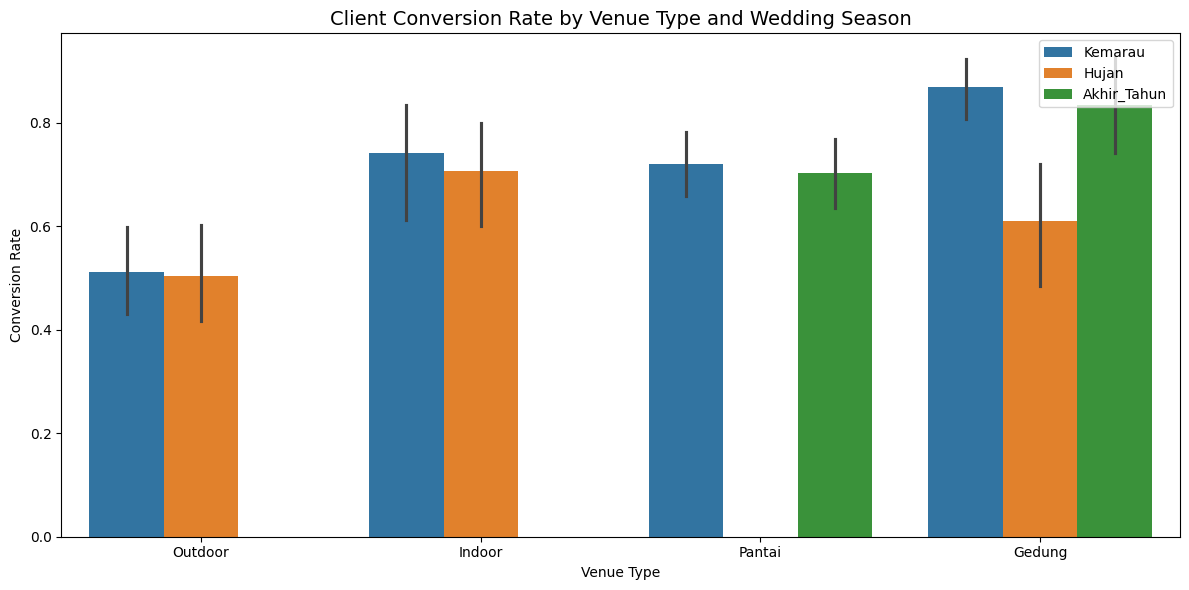

In [ ]:
musim_rate = data.groupby("musim_nikah")["deal_jadi"].mean().reset_index()
musim_rev = data.groupby("musim_nikah")["Revenue_terealisasi_juta"].sum().reset_index()
print("Conversion Rate per Musim:\n", musim_rate)
print("\nRealized Revenue per Musim:\n", musim_rev)

plt.figure(figsize=(12, 6))
sns.barplot(x="jenis_venue", y="deal_jadi", hue="musim_nikah", data=data)
plt.title("Client Conversion Rate by Venue Type and Wedding Season", fontsize=14)
plt.xlabel("Venue Type")
plt.ylabel("Conversion Rate")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

### C. Seasonal Impact on Conversion Rate Across Venue Types
Analyzing closing performance across wedding seasons (`musim_nikah`) highlighted how weather sensitivity directly shapes deal outcomes:
* **Kemarau (Dry Season):** Dominated total demand (513 leads) and realized revenue (**Rp 96,802 million**) with a **70.37%** conversion rate, led by **Gedung** (**86.82%**) and **Pantai** (**72.02%**).
* **Akhir_Tahun (Year-End):** Delivered the highest overall conversion rate at **73.19%** (235 leads; **Rp 57,264 million** revenue).
* **Hujan (Rainy Season):** Experienced a sharp drop in conversion rate to **59.13%** (252 leads; **Rp 26,264 million** revenue). Notably, **Pantai** recorded zero inquiries during the rainy season, while **Gedung** conversion fell from **86.82%** to **60.94%**.

Conversion Rate per Level Catering:
   level_catering  deal_jadi
0          Basic   0.516129
1           Gold   0.704110
2       Platinum   0.861789
3         Silver   0.657216

Conversion Rate per Jenis Dekorasi:
   jenis_dekorasi  deal_jadi
0      Minimalis   0.579767
1   Modern_Mewah   0.864000
2         Rustic   0.643002


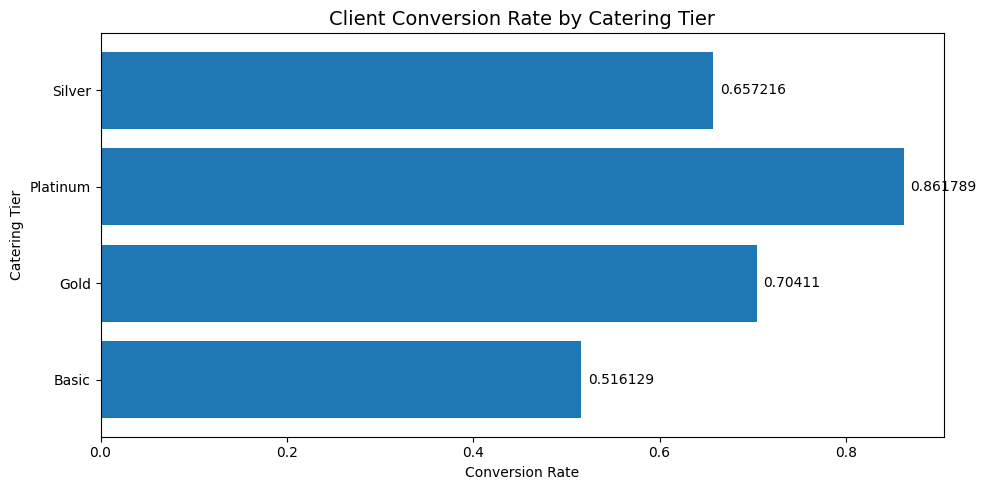

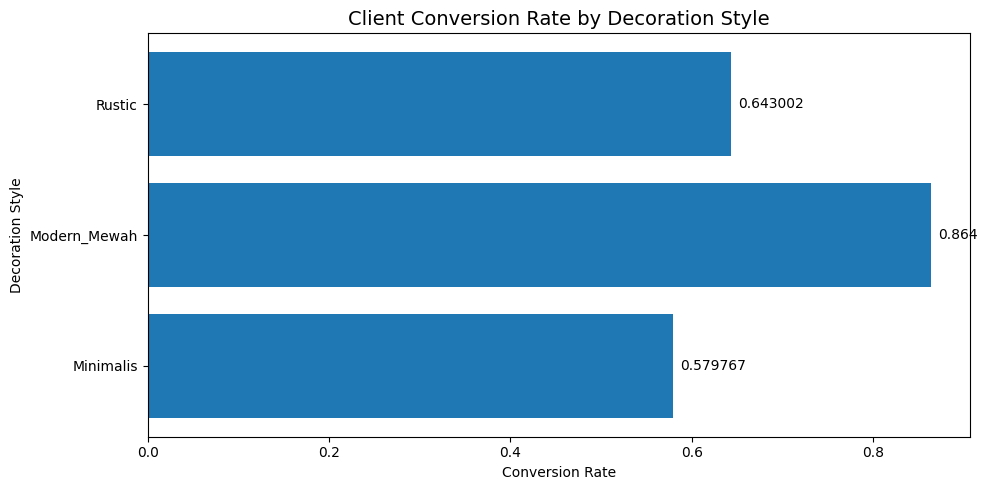

In [ ]:
catering_rate = data.groupby("level_catering")["deal_jadi"].mean().reset_index()
dekor_rate = data.groupby("jenis_dekorasi")["deal_jadi"].mean().reset_index()

print("Conversion Rate per Level Catering:\n", catering_rate)
print("\nConversion Rate per Jenis Dekorasi:\n", dekor_rate)

# Grafik 1: Conversion Rate per Level Catering
plt.figure(figsize=(10, 5))
bars_cat = plt.barh(catering_rate["level_catering"], catering_rate["deal_jadi"])
plt.bar_label(bars_cat, padding=5)
plt.title("Client Conversion Rate by Catering Tier", fontsize=14)
plt.xlabel("Conversion Rate")
plt.ylabel("Catering Tier")
plt.tight_layout()
plt.show()

# Grafik 2: Conversion Rate per Jenis Dekorasi
plt.figure(figsize=(10, 5))
bars_dek = plt.barh(dekor_rate["jenis_dekorasi"], dekor_rate["deal_jadi"])
plt.bar_label(bars_dek, padding=5)
plt.title("Client Conversion Rate by Decoration Style", fontsize=14)
plt.xlabel("Conversion Rate")
plt.ylabel("Decoration Style")
plt.tight_layout()
plt.show()

### D. Package Tier Conversion: Catering & Decoration
Evaluating closing rates across catering tiers and decoration themes revealed that premium-segment clients convert at significantly higher rates than budget-tier prospects:
* **Catering Tier Performance:** **Platinum** achieved an **86.18%** closing rate, followed by **Gold** (**70.41%**) and **Silver** (**65.72%**), whereas **Basic** catering dropped to **51.61%**.
* **Decoration Style Performance:** **Modern_Mewah** led all themes with an **86.40%** conversion rate, outperforming **Rustic** (**64.30%**) and **Minimalis** (**57.98%**).

           budget_juta  jumlah_undangan   jarak_km       usia  \
deal_jadi                                                       
0           203.176101       873.779874  22.515723  30.283019   
1           264.413490      1091.199413  21.274194  32.829912   

           Budget_per_undangan_ribu  
deal_jadi                            
0                        247.810054  
1                        264.997887  


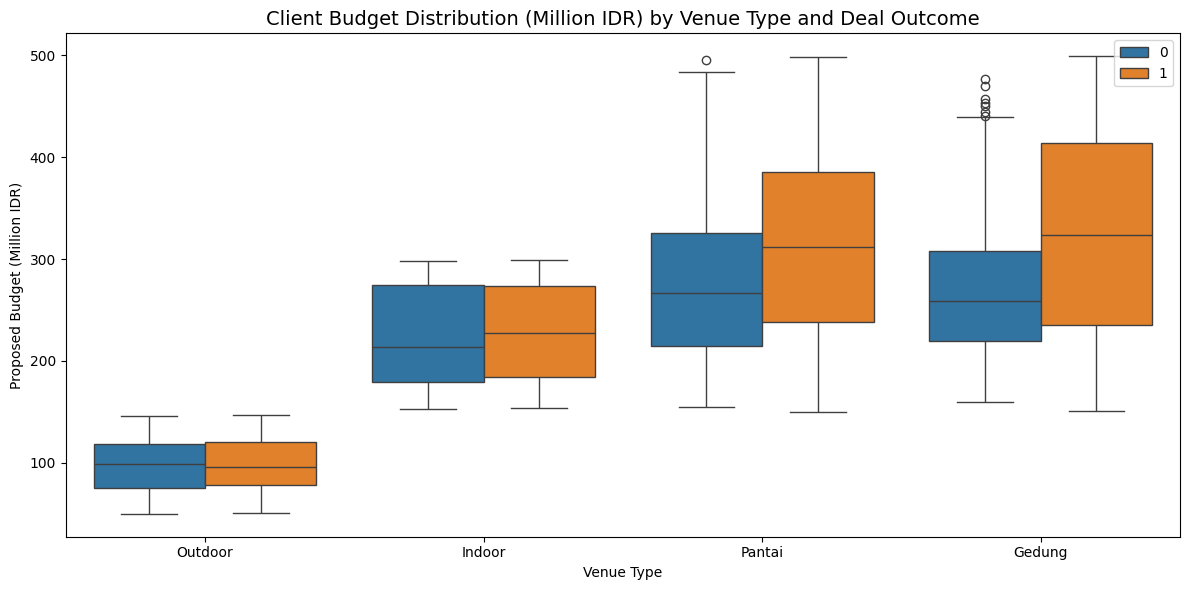

In [ ]:
profil_deal = data.groupby("deal_jadi")[["budget_juta", "jumlah_undangan", "jarak_km", "usia", "Budget_per_undangan_ribu"]].mean()
print(profil_deal)

plt.figure(figsize=(12, 6))
sns.boxplot(x="jenis_venue", y="budget_juta", hue="deal_jadi", data=data)
plt.title("Client Budget Distribution (Million IDR) by Venue Type and Deal Outcome", fontsize=14)
plt.xlabel("Venue Type")
plt.ylabel("Proposed Budget (Million IDR)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

### E. Client Budget & Profile Comparison: Deal vs. Lost
Comparing average client attributes between closed deals (`deal_jadi == 1`) and lost inquiries (`deal_jadi == 0`) confirmed distinct buyer profiles:
* **Higher Budget & Guest Capacity:** Closed deals averaged **Rp 264.41 million** in budget and **1,091 guests**, compared to **Rp 203.18 million** and **874 guests** among lost inquiries.
* **Budget per Guest & Age:** Closing clients allocated higher per-guest budgets (**Rp 265.00 thousand** vs. **Rp 247.81 thousand**) and tended to be slightly older (**32.83 years** vs. **30.28 years**), whereas venue distance (`jarak_km`) showed minimal variance (~21.3 km vs. ~22.5 km).

---

## Strategic Business & Sales Recommendations
* **Prioritize High-Intent Premium & Mid-Upper Leads:** Focus senior sales consultants on inquiries selecting **Platinum/Gold catering** and **Modern_Mewah decoration** (conversion >70–86%), as these segments represent the highest closing certainty and average ticket size (>Rp 264 million).
* **Restructure Outdoor & Entry-Level Packages:** Because **Outdoor** venues (**50.80%**) and **Basic/Minimalis** packages (**51.6–58.0%**) suffer high drop-off rates, introduce standardized all-in-one bundled packages with transparent pricing and weather-backup options to reduce client hesitation.
* **Rainy-Season Promotion & Venue Shifting:** Actively steer inquiries scheduled during **Musim Hujan** toward **Indoor** venues (which maintain a steady **70.67%** rainy-season conversion rate) and offer seasonal incentives for **Gedung** bookings to offset the sharp rainy-season dip.